# Лабораторная работа №4. Обучение адаптера LoRA

Базовая модель `Qwen3-0.6B`.

Цель - по отзыву с Яндекс Карт предсказать оценку автора от 1 до 5 (`mteb/GeoreviewClassification`).
Дообучение это тот же градиентный спуск по той же кросс-энтропии, только стартовые веса не случайные, а обновляются
не все веса, а маленькие матрицы адаптера. Вместо $W$ модель использует $W + \frac{\alpha}{r} B A$, где $A \in \mathbb{R}^{r \times d_{in}}$,
$B \in \mathbb{R}^{d_{out} \times r}$, $r = 8$, $\alpha = 16$; $W$ заморожена.

Данные, промпт и шаблон чата берутся из `run.py`, поэтому обучающий диалог совпадает с zero-shot один в один.
Ноутбук пишет в `artifacts/`: `adapter/`, `train_config.json`, `train_log.csv`, `train_loss.png`. Оценку трех режимов делает `python run.py`.

In [1]:
%matplotlib inline
import csv
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from peft import LoraConfig, get_peft_model

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
from run import (ADAPTER, ARTIFACTS, DATASET, DEVICE, DTYPE, MODEL, SEED, answer, build_messages,
                 load_data, load_model, parse_stars, peak_memory_gb, render, reset_memory, test_examples, train_examples)

LORA_R, LORA_ALPHA, LORA_DROPOUT = 8, 16, 0.05
TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
EPOCHS = 1
BATCH = 8                                                            # примеров на шаг оптимизатора
MICRO = 8                                                            # примеров на один проход
LR = 2e-4
MAX_LEN = 256                                                        # токенов в обучающем примере
LOG_EVERY = 25                                                       # шагов между строками train_log.csv

torch.manual_seed(SEED)
ARTIFACTS.mkdir(exist_ok=True)
print("устройство", DEVICE, "\ndtype", DTYPE, "\ntorch", torch.__version__)

устройство cuda 
dtype torch.float32 
torch 2.11.0+cu128


## 1. Данные

Из `train` по 1000 примеров на класс с seed 0, всего 5000. Порядок перемешан, чтобы в каждом батче были разные классы.

In [4]:
ds = load_data()
train = train_examples(ds)
print(ds)
print("обучающих примеров", len(train), "| по классам", {c: sum(ex["label"] == c for ex in train) for c in range(1, 6)})
print("первые метки", [ex["label"] for ex in train[:20]])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2048
    })
})
обучающих примеров 5000 | по классам {1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000}
первые метки [1, 5, 2, 1, 4, 2, 5, 3, 2, 5, 4, 5, 5, 2, 3, 2, 2, 2, 5, 3]


## 2. Обучающий пример и маска лосса

Пример это тот же диалог, что в zero-shot, плюс ответ ассистента, цифра и `<|im_end|>`. Лосс считается только по токенам ответа,
у токенов промпта метка $-100$, и `cross_entropy` их пропускает:

$$\mathcal{L} = -\frac{1}{|A|}\sum_{t \in A} \log p_\theta(x_t \mid x_{<t}),$$

где $A$ это позиции ответа. Если пример длиннее 256 токенов, обрезается конец отзыва, а системная строка и шаблон остаются.

In [7]:
tokenizer, model = load_model()


def encode(ex):
    """Токены диалога с ответом и метки: -100 на промпте, номера токенов на ответе."""
    ans = tokenizer(f"{ex['label']}<|im_end|>", add_special_tokens=False)["input_ids"]  # цифра и конец реплики
    text = ex["text"]
    prompt = tokenizer(render(tokenizer, build_messages(text)), add_special_tokens=False)["input_ids"]
    while len(prompt) + len(ans) > MAX_LEN:                                               # режем хвост отзыва
        ids = tokenizer(text, add_special_tokens=False)["input_ids"]
        text = tokenizer.decode(ids[: len(ids) - (len(prompt) + len(ans) - MAX_LEN)])
        prompt = tokenizer(render(tokenizer, build_messages(text)), add_special_tokens=False)["input_ids"]
    return {"input_ids": prompt + ans, "labels": [-100] * len(prompt) + ans, "cut": text != ex["text"]}


encoded = [encode(ex) for ex in train]
lengths = [len(e["input_ids"]) for e in encoded]
print("длина примера: средняя", round(sum(lengths) / len(lengths), 1), "| максимум", max(lengths),
      "| обрезано", sum(e["cut"] for e in encoded))

e = encoded[0]
print(tokenizer.decode(e["input_ids"]))
print("токены, по которым считается лосс:", [tokenizer.decode([t]) for t in e["labels"] if t != -100])

C:\Users\StaxMan\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\StaxMan\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

C:\Users\StaxMan\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\StaxMan\.cache\huggingface\hub\models--Qwen--Qwen3-0.6B. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

длина примера: средняя 221.2 | максимум 256 | обрезано 1990
<|im_start|>system
Ты оцениваешь отзывы об организациях с Яндекс Карт. По тексту отзыва определи оценку, которую поставил автор, по шкале от 1 до 5: 1 — очень плохо, 2 — плохо, 3 — средне, 4 — хорошо, 5 — отлично. Ответь одной цифрой от 1 до 5 без пояснений.<|im_end|>
<|im_start|>user
Отзыв: За последний год обслуживания - убили машину. Приемщик Антон просто сдирает деньги без ремонта.  Как факт - провел экспертизу после их ремонтов, за который отдал не мало средств - показала лишь 15% замены, вместо того, что указано на бумаге. В итоге около 60 000 выброшено на ветер или в карманы сотрудников компании. Судится с ними? Нет. Но не рекомендую! Халява и жлоб

Оценка автора (одна цифра от 1 до 5):<|im_end|>
<|im_start|>assistant
<think>

</think>

1<|im_end|>
токены, по которым считается лосс: ['1', '<|im_end|>']


## 3. Адаптер LoRA

Ранг 8, $\alpha = 16$ на всех линейных слоях внимания и полносвязной сети. Общее число параметров считается по базовой модели
до подключения адаптера, доля обучаемых это их отношение.

In [10]:
total_params = sum(p.numel() for p in model.parameters())                                 # базовая модель, связанные веса один раз
torch.manual_seed(SEED)                                                                  # инициализация матриц A
config = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                    target_modules=TARGETS, bias="none", task_type="CAUSAL_LM")
model = get_peft_model(model, config)
model.config.use_cache = False                                                           # кэш при обучении не нужен
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
trainable_pct = round(100 * trainable_params / total_params, 3)
print(f"обучаемых {trainable_params:,} из {total_params:,} ({trainable_pct} %)")

обучаемых 5,046,272 из 596,049,920 (0.847 %)


## 4. Обучение

Одна эпоха, `AdamW`, шаг $2 \cdot 10^{-4}$, батч 8 примеров. Если 8 примеров за проход не помещаются в память, `MICRO` уменьшается,
а градиент накапливается за `BATCH // MICRO` проходов. В журнал пишется средний лосс за последние 25 шагов.

In [13]:
def collate(items):
    """Дополнение справа: pad-токены с маской 0 и меткой -100."""
    n = max(len(e["input_ids"]) for e in items)
    pad = tokenizer.pad_token_id
    ids = [e["input_ids"] + [pad] * (n - len(e["input_ids"])) for e in items]
    mask = [[1] * len(e["input_ids"]) + [0] * (n - len(e["input_ids"])) for e in items]
    labels = [e["labels"] + [-100] * (n - len(e["labels"])) for e in items]
    return [torch.tensor(x, device=DEVICE) for x in (ids, mask, labels)]


opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR)
accum = BATCH // MICRO
steps = EPOCHS * len(encoded) // BATCH
log, window = [], []
model.train()
reset_memory()
start = time.perf_counter()
for step in range(1, steps + 1):
    batch = encoded[((step - 1) * BATCH) % len(encoded):][:BATCH]
    opt.zero_grad()
    step_loss = 0.0
    for k in range(0, BATCH, MICRO):                                                     # накопление градиента
        ids, mask, labels = collate(batch[k:k + MICRO])
        loss = model(input_ids=ids, attention_mask=mask, labels=labels).loss / accum      # сдвиг меток внутри модели
        loss.backward()
        step_loss += loss.item()
    opt.step()
    window.append(step_loss)
    if step == 1 or step % LOG_EVERY == 0 or step == steps:
        log.append((step, round(sum(window) / len(window), 4)))
        window = []
        print(f"шаг {step:4d}/{steps} | лосс {log[-1][1]:.4f} | {time.perf_counter() - start:6.0f} с")
if DEVICE == "cuda":
    torch.cuda.synchronize()
train_minutes = round((time.perf_counter() - start) / 60, 2)
train_peak = peak_memory_gb()
print("время", train_minutes, "мин | пиковая память", train_peak, "ГБ")

шаг    1/625 | лосс 1.2579 |     18 с
шаг   25/625 | лосс 0.7192 |     28 с
шаг   50/625 | лосс 0.5876 |     37 с
шаг   75/625 | лосс 0.5654 |     47 с
шаг  100/625 | лосс 0.6069 |     56 с
шаг  125/625 | лосс 0.5415 |     65 с
шаг  150/625 | лосс 0.5326 |     75 с
шаг  175/625 | лосс 0.5606 |     84 с
шаг  200/625 | лосс 0.5469 |     94 с
шаг  225/625 | лосс 0.5427 |    103 с
шаг  250/625 | лосс 0.5805 |    112 с
шаг  275/625 | лосс 0.5272 |    121 с
шаг  300/625 | лосс 0.5307 |    131 с
шаг  325/625 | лосс 0.4941 |    140 с
шаг  350/625 | лосс 0.5323 |    149 с
шаг  375/625 | лосс 0.5305 |    159 с
шаг  400/625 | лосс 0.5002 |    168 с
шаг  425/625 | лосс 0.5060 |    177 с
шаг  450/625 | лосс 0.5365 |    187 с
шаг  475/625 | лосс 0.5000 |    196 с
шаг  500/625 | лосс 0.5677 |    205 с
шаг  525/625 | лосс 0.5031 |    215 с
шаг  550/625 | лосс 0.4940 |    224 с
шаг  575/625 | лосс 0.5009 |    233 с
шаг  600/625 | лосс 0.5074 |    243 с
шаг  625/625 | лосс 0.4975 |    252 с
время 4.2 ми

## 5. Сохранение адаптера и артефактов

`save_pretrained` пишет только матрицы адаптера (`adapter_model.safetensors`) и его конфигурацию, веса базовой модели не сохраняются.

In [16]:
model.save_pretrained(ADAPTER)

with open(ARTIFACTS / "train_log.csv", "w", encoding="utf-8", newline="") as f:
    w = csv.writer(f)
    w.writerow(["step", "loss"])
    w.writerows(log)

train_config = {"model": MODEL, "dataset": DATASET, "lora_r": LORA_R, "lora_alpha": LORA_ALPHA, "lora_dropout": LORA_DROPOUT,
                "target_modules": TARGETS, "trainable_params": trainable_params, "total_params": total_params,
                "trainable_pct": trainable_pct, "train_examples": len(encoded), "epochs": EPOCHS, "steps": steps,
                "batch": BATCH, "micro_batch": MICRO, "lr": LR, "max_len": MAX_LEN, "train_minutes": train_minutes,
                "peak_memory_gb": train_peak, "device": DEVICE, "dtype": str(DTYPE).replace("torch.", ""), "seed": SEED}
(ARTIFACTS / "train_config.json").write_text(json.dumps(train_config, ensure_ascii=False, indent=1), encoding="utf-8")
print(json.dumps(train_config, ensure_ascii=False, indent=1))
print(sorted(p.name for p in ADAPTER.iterdir()), round((ADAPTER / "adapter_model.safetensors").stat().st_size / 2**20, 1), "МБ")

{
 "model": "Qwen/Qwen3-0.6B",
 "dataset": "mteb/GeoreviewClassification",
 "lora_r": 8,
 "lora_alpha": 16,
 "lora_dropout": 0.05,
 "target_modules": [
  "q_proj",
  "k_proj",
  "v_proj",
  "o_proj",
  "gate_proj",
  "up_proj",
  "down_proj"
 ],
 "trainable_params": 5046272,
 "total_params": 596049920,
 "trainable_pct": 0.847,
 "train_examples": 5000,
 "epochs": 1,
 "steps": 625,
 "batch": 8,
 "micro_batch": 8,
 "lr": 0.0002,
 "max_len": 256,
 "train_minutes": 4.2,
 "peak_memory_gb": 13.39,
 "device": "cuda",
 "dtype": "float32",
 "seed": 0
}
['README.md', 'adapter_config.json', 'adapter_model.safetensors'] 19.3 МБ


## 6. Кривая лосса

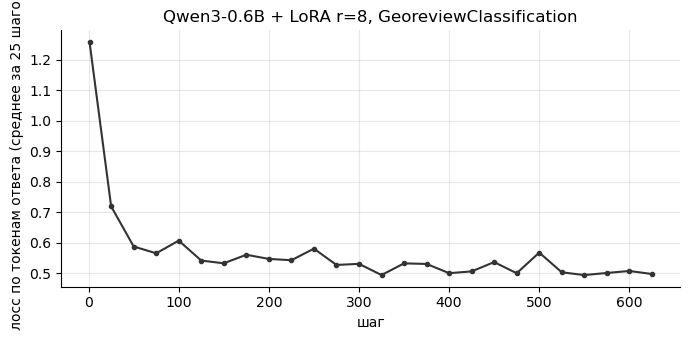

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([s for s, _ in log], [l for _, l in log], marker="o", markersize=3, color="#333333")
ax.set_xlabel("шаг")
ax.set_ylabel(f"лосс по токенам ответа (среднее за {LOG_EVERY} шагов)")
ax.set_title("Qwen3-0.6B + LoRA r=8, GeoreviewClassification")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(ARTIFACTS / "train_loss.png", dpi=150)
plt.show()

## 7. Проверка на нескольких тестовых отзывах

Короткая проверка, что адаптер отвечает цифрой. Полная оценка трех режимов: `python run.py`.

In [22]:
model.eval()
model.config.use_cache = True                                                            # для генерации кэш снова нужен
for ex in test_examples(ds, 8):
    raw, _ = answer(tokenizer, model, render(tokenizer, build_messages(ex["text"])))
    print(f"метка {ex['label']} | ответ {raw!r} -> {parse_stars(raw)} | {ex['text'][:80]!r}")

метка 3 | ответ '3' -> 3 | 'Делала маникюр и педикюр в этом салоне. Салон неряшливый, видно что работникам в'
метка 4 | ответ '5' -> 5 | 'Уютная гостиница, вежливый персонал, чисто. В номере все есть и все исправно). М'
метка 2 | ответ '3' -> 3 | 'Две звезды за напитки и десерт. \\nВ остальном все очень печально. Ждали еду очен'
метка 3 | ответ '5' -> 5 | 'Александра очень доброжелательна, мастер своего дела! Сделала мне красивый макия'
метка 3 | ответ '1' -> 1 | 'Время 10:05, стоим 15 минут, никого нет. У вас кофейня работает?Если не работает'
метка 1 | ответ '2' -> 2 | 'я не понимаю, кому в наше время вообще нужны безнадёжно Устаревшие CD/DVD диски,'
метка 5 | ответ '5' -> 5 | 'Спасибо огромное турагенству coral travel за профессионализм, качественную работ'
метка 1 | ответ '2' -> 2 | 'Подача бургера несоответствует  меню. \\nВсе холодное кроме чая.  Все плохо . Бур'
